# 확률 분포와 손실 함수의 수학적 연결

정규분포, 베르누이, 소프트맥스, MLE, 정보 이론을 NumPy로 확인한다.
$N(\mu,\sigma^2)$ 관례를 사용하므로 $N(2,0.5)$의
분산은 0.5, 표준편차는 $\sqrt{0.5}$이다. 모든 log는 자연로그다.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
(ROOT / "outputs").mkdir(exist_ok=True)
np.random.seed(42)
np.set_printoptions(precision=10, suppress=True)

## 1. 정규분포 PDF와 베르누이 PMF
$$p(x|\mu,\sigma^2)=\frac1{\sqrt{2\pi\sigma^2}}
\exp\left[-\frac{(x-\mu)^2}{2\sigma^2}\right].$$
연속분포의 확률은 PDF의 구간 적분이며 한 점에서의 높이가 아니다.
$$P(X=x)=p^x(1-p)^{1-x},\qquad x\in\{0,1\}.$$

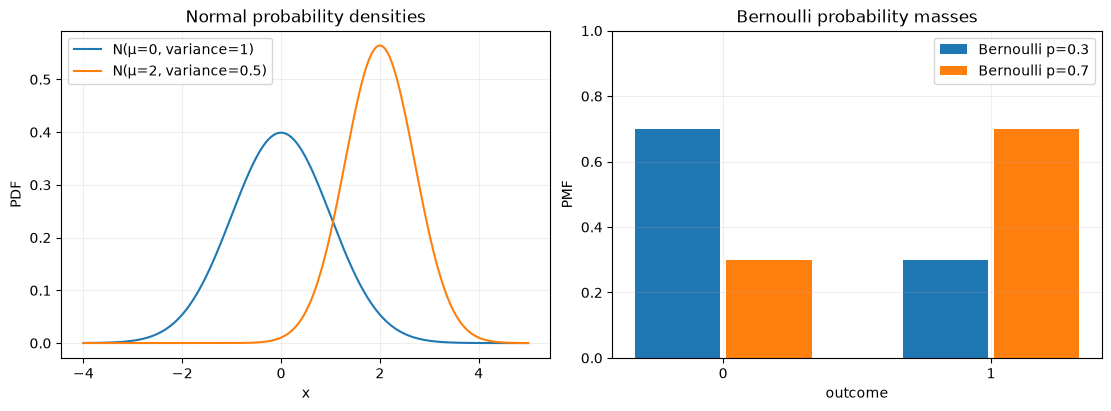

Normal 0 1 integral 1.0
Normal 2 0.5 integral 1.0
Bernoulli 0.3 [0.7 0.3]
Bernoulli 0.7 [0.3 0.7]


In [2]:
from src.probability import (
    normal_pdf, bernoulli_pmf, softmax, plot_distributions,
    entropy, cross_entropy, kl_divergence)
fig = plot_distributions()
fig.savefig(ROOT / "outputs/probability_distributions.png", dpi=150)
plt.show()
grid = np.linspace(-12, 12, 20001)
for mean, variance in [(0, 1), (2, 0.5)]:
    density = normal_pdf(grid, mean, variance)
    # Composite trapezoidal integration written directly in NumPy.
    integral = np.sum((density[:-1] + density[1:]) * np.diff(grid) / 2)
    print("Normal", mean, variance, "integral", integral)
    assert abs(integral - 1) < 1e-6
for p in [0.3, 0.7]:
    print("Bernoulli", p, bernoulli_pmf(p))
    assert abs(bernoulli_pmf(p).sum() - 1) < 1e-12

## 2. 소프트맥스와 수치 안정성
$$q_k=\frac{\exp(z_k-m)}{\sum_j\exp(z_j-m)},\qquad m=\max_jz_j.$$
같은 상수 $m$을 빼도 비율은 같고 큰 logit에서 overflow를 피한다.
softmax는 비음수 확률을 만들고 총합을 1로 정규화한다.

In [3]:
logits = np.array([1000., 1001., 1002.])
probabilities = softmax(logits)
print("softmax", probabilities, "sum", probabilities.sum())
assert abs(probabilities.sum() - 1) < 1e-6
np.testing.assert_allclose(probabilities, softmax(logits - 1000))
for extreme in [[10000., 10001., 10002.], [-10000., -10001., -10002.],
                [1000., -1000., 0.], [-1e6, -1e6, -1e6]]:
    with np.errstate(over="raise", invalid="raise"):
        result = softmax(extreme)
    assert np.isfinite(result).all()
    assert abs(result.sum() - 1) < 1e-6
    np.testing.assert_allclose(result, softmax(np.array(extreme) - np.max(extreme)))
    print("extreme logits:", extreme, "probabilities:", result, "sum:", result.sum())

softmax [0.0900305732 0.2447284711 0.6652409558] sum 0.9999999999999999
extreme logits: [10000.0, 10001.0, 10002.0] probabilities: [0.0900305732 0.2447284711 0.6652409558] sum: 0.9999999999999999
extreme logits: [-10000.0, -10001.0, -10002.0] probabilities: [0.6652409558 0.2447284711 0.0900305732] sum: 0.9999999999999999
extreme logits: [1000.0, -1000.0, 0.0] probabilities: [1. 0. 0.] sum: 1.0
extreme logits: [-1000000.0, -1000000.0, -1000000.0] probabilities: [0.3333333333 0.3333333333 0.3333333333] sum: 1.0


## 3. MSE 최소화 = 정규 잡음 가정 아래의 MLE

가정: 관측치는 조건부 독립이고
$y_i=f_\theta(x_i)+\epsilon_i$,
$\epsilon_i\sim N(0,\sigma^2)$이다.
$\sigma^2>0$는 모든 표본에서 같고 $\theta$와 무관한 고정값이다.

$$\mathcal L(\theta)=\prod_{i=1}^n
\frac1{\sqrt{2\pi\sigma^2}}
\exp\left[-\frac{(y_i-f_\theta(x_i))^2}{2\sigma^2}\right].$$

$$\log\mathcal L(\theta)
=-\frac n2\log(2\pi\sigma^2)
-\frac1{2\sigma^2}\sum_i(y_i-f_\theta(x_i))^2.$$

따라서
$$\arg\max_\theta\mathcal L
=\arg\min_\theta[-\log\mathcal L]
=\arg\min_\theta\sum_i(y_i-f_\theta(x_i))^2
=\arg\min_\theta\frac1n\sum_i(y_i-f_\theta(x_i))^2.$$

고정된 양의 배율과 $\theta$에 무관한 상수를 제거했으므로 최적점이 같다.
**MSE와 NLL의 숫자 자체가 같은 것은 아니다.**
분산이 표본마다 다르면 가중 제곱오차가 되고,
분산도 모델이 예측하면 log 분산 항을 버릴 수 없다.

In [4]:
observed = np.array([0.2, 0.8, 1.4])
candidate_means = np.linspace(-1, 2, 301)
variance = 0.5
residuals = observed[None, :] - candidate_means[:, None]
mse = np.mean(residuals**2, axis=1)
nll = (len(observed) / 2 * np.log(2*np.pi*variance)
       + np.sum(residuals**2, axis=1)/(2*variance))
np.testing.assert_allclose(nll, len(observed)*mse/(2*variance)
                           + len(observed)/2*np.log(2*np.pi*variance))
assert np.argmin(mse) == np.argmin(nll)
print("Gaussian MLE and MSE choose mean =", candidate_means[np.argmin(mse)])

Gaussian MLE and MSE choose mean = 0.8


## 4. Binary Cross-Entropy 최소화 = 베르누이 MLE

$y_i\in\{0,1\}$, $p_i=f_\theta(x_i)\in(0,1)$라 하자.
$$P(y_i|x_i;\theta)=p_i^{y_i}(1-p_i)^{1-y_i}.$$
조건부 독립 표본의 log likelihood는
$$\log\mathcal L(\theta)=
\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)].$$
$$-\frac1n\log\mathcal L(\theta)
=-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]
=\operatorname{BCE}.$$
즉 베르누이 확률의 최대우도 추정과 평균 BCE 최소화는 동일한 최적점이다.

## 5. Categorical Cross-Entropy 최소화 = 카테고리 MLE

$y_{ik}$는 정답의 one-hot 성분이고 $q_{ik}$는 softmax 확률이다.
$$P(y_i|x_i;\theta)=\prod_{k=1}^K q_{ik}^{y_{ik}},$$
$$-\frac1n\log\mathcal L(\theta)
=-\frac1n\sum_i\sum_k y_{ik}\log q_{ik}
=\operatorname{CategoricalCE}.$$

회귀의 연속 오차에는 정규분포, 이진 분류에는 베르누이,
상호 배타적인 다중 분류에는 카테고리 분포를 사용한다.

In [5]:
targets = np.array([0., 1., 1.])
p = np.array([0.2, 0.8, 0.7])
bce_sum = -np.sum(targets*np.log(p)+(1-targets)*np.log1p(-p))
likelihood = np.prod(p**targets * (1-p)**(1-targets))
np.testing.assert_allclose(bce_sum, -np.log(likelihood))
one_hot = np.array([[1., 0., 0.], [0., 0., 1.]])
q = softmax(np.array([[2., 1., 0.], [0., 1., 2.]]), axis=1)
ce_sum = -np.sum(one_hot * np.log(q))
categorical_likelihood = np.prod(q[one_hot.astype(bool)])
np.testing.assert_allclose(ce_sum, -np.log(categorical_likelihood))
print("Bernoulli summed NLL =", bce_sum, "; categorical summed NLL =", ce_sum)

Bernoulli summed NLL = 0.8029620465671519 ; categorical summed NLL = 0.8152119288887609


## 6. 보너스: Entropy, KL-Divergence, Cross-Entropy

$$H(p)=-\sum_kp_k\log p_k,$$
$$D_{KL}(p\Vert q)=\sum_kp_k\log\frac{p_k}{q_k},$$
$$H(p,q)=-\sum_kp_k\log q_k=H(p)+D_{KL}(p\Vert q).$$

$0\log0=0$으로 정의한다. $p_k>0$인데 $q_k=0$이면
Cross-Entropy와 KL은 무한대다. 단위는 nats이며 KL은 비대칭이다.
데이터의 정답 분포 $p$가 고정되면 Cross-Entropy를 줄이는 것은
예측 분포와의 KL을 줄이는 것과 같다.

In [6]:
p, q = np.array([.3, .7]), np.array([.6, .4])
h, ce, kl = entropy(p), cross_entropy(p, q), kl_divergence(p, q)
print("H(p) =", h, "H(p,q) =", ce, "KL(p||q) =", kl)
assert abs(ce-h-kl) < 1e-12
assert kl >= -1e-12
assert entropy([1., 0.]) == 0
assert np.isinf(kl_divergence([1., 0.], [0., 1.]))
print("Information-theory identities and boundary cases PASS.")

H(p) = 0.6108643020548935 H(p,q) = 0.7946511994417057 KL(p||q) = 0.1837868973868122
Information-theory identities and boundary cases PASS.
